In [1]:
# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#   kernelspec:
#     display_name: Python 3
#     language: python
#     name: python3
# ---

# 03 · Difference-in-differences: did the toll reduce trips?

**Design.** Units are pickup zones, observed weekly. Treated: the 38 CBD
zones (all trips starting there). Comparison: zones in the rest of
Manhattan (trips that do not end in the CBD). The six border zones and the
airports are left out. Regressions include zone and week fixed effects,
weight zones by their average pre-toll trips (so the answer is about
trips, not about the median zone), and cluster standard errors by zone.

**Plan.**
1. The quick answer: 2025 against 2024.
2. The same comparison one year earlier, when there was no toll.
3. An event study that shows the whole path.
4. The main estimate, which allows every zone its own trend, and (4b) how
   much "effect" it finds on fake toll dates.
5. Robustness: services, comparison groups, weighting, a within-origin design.
6. What else changed: trip speed, waits, fares, driver pay, shared rides, time of day.
7. How much the fee raised the price of a CBD trip.

In [2]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from congestion.did import event_study, fit_did, fit_did_pre_trend
from congestion.panel import (FIRST_POST_WEEK, SERVICE_LABEL, WINDOW_START, YEAR1_END, flow_week_panel,
                              load_zone_day, window, zone_week_outcomes, zone_week_panel)
from congestion.zones import MANHATTAN_ZONES
from congestion.plots import COLORS, mark_policy, save, style, write_metrics

style()
pd.set_option("display.width", 140)

zd = load_zone_day()
panels = {svc: zone_week_panel(zd, svc) for svc in [("yellow", "hvfhv"), ("hvfhv",), ("yellow",)]}
POOLED = panels[("yellow", "hvfhv")]
print("Pooled panel:", POOLED["pu_zone"].nunique(), "zones,", POOLED["week"].nunique(), "weeks,",
      POOLED["week"].min().date(), "to", POOLED["week"].max().date())


def comparison(panel, group):
    """Keep CBD zones plus one comparison group ('manhattan_north', 'outer' or 'both')."""
    from congestion.zones import zone_group
    g = panel["pu_zone"].map(zone_group)
    return panel if group == "both" else panel[g.isin(["cbd", group])]


def fmt(r):
    return f"{r.pct:+.1%} (95% CI {r.pct_ci[0]:+.1%} to {r.pct_ci[1]:+.1%})"


MAIN = comparison(POOLED, "manhattan_north")
print("Treated zones:", MAIN.loc[MAIN["treated"], "pu_zone"].nunique(),
      "| comparison zones:", MAIN.loc[~MAIN["treated"], "pu_zone"].nunique())

Pooled panel: 248 zones, 242 weeks, 2022-01-03 to 2026-08-24
Treated zones: 38 | comparison zones: 22


## 1. The quick answer: 2025 against 2024

In [3]:
Y2024 = ("2024-01-08", "2024-12-22")
Y2025 = ("2025-01-06", "2025-12-21")      # same 50 calendar weeks
Y2023 = ("2023-01-09", "2023-12-24")

quick = window(MAIN, Y2024[0], Y2025[1], Y2025[0])
quick = quick[(quick["week"] <= Y2024[1]) | (quick["week"] >= Y2025[0])]
r_quick = fit_did(quick, weights="pre_mean_trips")
print("2025 vs 2024:", fmt(r_quick))

2025 vs 2024: -2.6% (95% CI -4.0% to -1.2%)


Taken at face value: trips starting in the CBD fell about 2-3% relative to
the rest of Manhattan in the toll's first year. A published early study
using only Uber/Lyft and the first 14 weeks found about −6%.

## 2. The same comparison a year earlier (no toll)

In [4]:
placebo = window(MAIN, Y2023[0], Y2024[1], Y2024[0])
placebo = placebo[(placebo["week"] <= Y2023[1]) | (placebo["week"] >= Y2024[0])]
r_placebo = fit_did(placebo, weights="pre_mean_trips")
print("2024 vs 2023 (placebo):", fmt(r_placebo))

2024 vs 2023 (placebo): -4.4% (95% CI -5.3% to -3.5%)


**The placebo year shows a gap at least as large.** From 2023 to 2024,
with no toll, CBD trips already fell relative to the rest of Manhattan by
about as much as from 2024 to 2025. The quick answer is mostly measuring a
trend that was already under way.

## 3. Event study

The CBD-minus-comparison gap in 13-week (quarterly) bins, relative to the
quarter before the toll. Parallel trends would show flat bars before the
toll; instead they slope down.

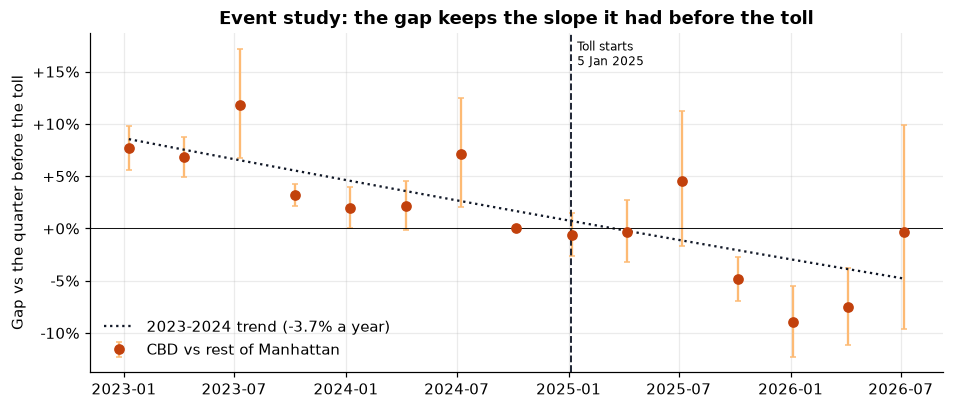

,bin,start_week,pct,pct_ci_low,pct_ci_high,pre_trend
0,-8,2023-01-09,0.077,0.056,0.098,0.085
1,-7,2023-04-10,0.068,0.050,0.088,0.075
2,-6,2023-07-10,0.118,0.067,0.172,0.065
3,-5,2023-10-09,0.032,0.021,0.043,0.055
4,-4,2024-01-08,0.020,0.001,0.039,0.046
5,-3,2024-04-08,0.022,-0.001,0.045,0.036
6,-2,2024-07-08,0.071,0.021,0.125,0.026
7,-1,2024-10-07,0.000,0.000,0.000,0.017
8,0,2025-01-06,-0.006,-0.026,0.014,0.007
9,1,2025-04-07,-0.003,-0.032,0.027,-0.002


In [5]:
es_panel = window(MAIN, WINDOW_START, MAIN["week"].max())
es = event_study(es_panel, weights="pre_mean_trips", policy_week=FIRST_POST_WEEK, bin_weeks=13)
pre_es = es[es["bin"] < 0]
slope, icpt = np.polyfit(pre_es["bin"], pre_es["beta"], 1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(es["start_week"], es["pct"], yerr=[es["pct"] - es["pct_ci_low"], es["pct_ci_high"] - es["pct"]],
            fmt="o", color=COLORS["cbd"], ecolor="#FDBA74", capsize=2, label="CBD vs rest of Manhattan")
ax.plot(es["start_week"], np.expm1(icpt + slope * es["bin"]), ls=":", color=COLORS["policy"],
        label=f"2023-2024 trend ({np.expm1(slope * 4):+.1%} a year)")
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("Gap vs the quarter before the toll")
ax.set_title("Event study: the gap keeps the slope it had before the toll")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.legend(loc="lower left")
mark_policy(ax)
save(fig, "03_event_study.png")
plt.show()
es_out = es[["bin", "start_week", "pct", "pct_ci_low", "pct_ci_high"]].copy()
es_out["pre_trend"] = np.expm1(icpt + slope * es["bin"])
es_out["start_week"] = es_out["start_week"].dt.date.astype(str)
es_out.to_csv("reports/metrics/event_study.csv", index=False)   # read by the app
es_out.round({"pct": 3, "pct_ci_low": 3, "pct_ci_high": 3, "pre_trend": 3})

The pre-toll quarters fall along a straight line, and the 2025 quarters
continue on (or slightly above) that line. The large drop in early 2026
breaks below it.

## 4. Main estimate: allowing each zone its own trend

The model adds a linear trend for every zone, fitted over two pre-toll
years (2023-2024) and the first toll year (2025). The toll effect is then
the break from each zone's own path. Year 2 (January-August 2026) is
estimated separately against the same trends.

In [6]:
main_win = window(MAIN, WINDOW_START, YEAR1_END)
r_main = fit_did(main_win, weights="pre_mean_trips", unit_trends=True)
print("Year 1 (2025), trend-adjusted:", fmt(r_main))

y2_win = window(MAIN, WINDOW_START, MAIN["week"].max(), "2026-01-05")
y2_win = y2_win[(y2_win["week"] < FIRST_POST_WEEK) | (y2_win["week"] >= "2026-01-05")]
r_y2 = fit_did(y2_win, weights="pre_mean_trips", unit_trends=True)
print("Year 2 (Jan-Aug 2026), trend-adjusted:", fmt(r_y2))

pl_win = window(MAIN, "2022-07-04", Y2024[1], Y2024[0])
r_pl_trend = fit_did(pl_win, weights="pre_mean_trips", unit_trends=True)
print("Placebo 2024, trend-adjusted:", fmt(r_pl_trend))

Year 1 (2025), trend-adjusted: +1.0% (95% CI -0.3% to +2.3%)


Year 2 (Jan-Aug 2026), trend-adjusted: -3.6% (95% CI -6.0% to -1.1%)


Placebo 2024, trend-adjusted: +2.0% (95% CI +0.9% to +3.1%)


Once each zone's trend is allowed for, the toll's first-year effect on
taxi and ride-hail trips starting in the CBD is **about zero** (+1.0%,
95% CI −0.3% to +2.3%). That interval only reflects sampling noise; the
next section measures how far off the method itself can be.

Year 2 (January-August 2026) shows −3.6%. It rests on extrapolating each
zone's trend further out and coincides with a Manhattan-wide drop in early
2026, so it is reported, with less confidence, as a possible second-year
decline to watch.

## 4b. How much "effect" does each method find when nothing happened?

Run both designs on pre-toll data only, pretending the toll started on
each of seven dates four weeks apart (July 2023 to January 2024). Each run
uses data from July 2022 (after the post-pandemic rebound) to 51 weeks
after its fake date, all before the real toll. A method that works should
find about zero every time.

In [7]:
PRE_ONLY = MAIN[MAIN["week"] < pd.Timestamp("2024-12-30")]
FAKE_DATES = pd.date_range("2023-07-03", "2024-01-01", freq="4W-MON")
fake_rows = []
for s in FAKE_DATES:
    w = window(PRE_ONLY, "2022-07-04", s + pd.Timedelta(weeks=51), s)
    fake_rows.append({"fake_start": s.date().isoformat(),
                      "quick": fit_did(w, weights="pre_mean_trips").pct,
                      "trend_adjusted": fit_did(w, weights="pre_mean_trips", unit_trends=True).pct,
                      "pre_trend_two_step": fit_did_pre_trend(w, weights="pre_mean_trips").pct})
fake = pd.DataFrame(fake_rows)
fake.to_csv("reports/metrics/did_fake_dates.csv", index=False)
fake_rms = {c: float(np.sqrt((fake[c] ** 2).mean())) for c in ["quick", "trend_adjusted", "pre_trend_two_step"]}
print("Typical size of a fake effect (root mean square):",
      {k: f"{v:.1%}" for k, v in fake_rms.items()})
fake.style.format({"quick": "{:+.1%}", "trend_adjusted": "{:+.1%}", "pre_trend_two_step": "{:+.1%}"})

Typical size of a fake effect (root mean square): {'quick': '6.4%', 'trend_adjusted': '4.3%', 'pre_trend_two_step': '4.2%'}


,fake_start,quick,trend_adjusted,pre_trend_two_step
0,2023-07-03,-5.2%,+7.9%,+9.6%
1,2023-07-31,-5.9%,+2.2%,+4.4%
2,2023-08-28,-6.1%,-0.0%,+2.8%
3,2023-09-25,-6.2%,-1.7%,+1.8%
4,2023-10-23,-6.6%,-3.4%,+0.3%
5,2023-11-20,-7.1%,-5.6%,-1.3%
6,2023-12-18,-7.0%,-4.2%,-0.3%


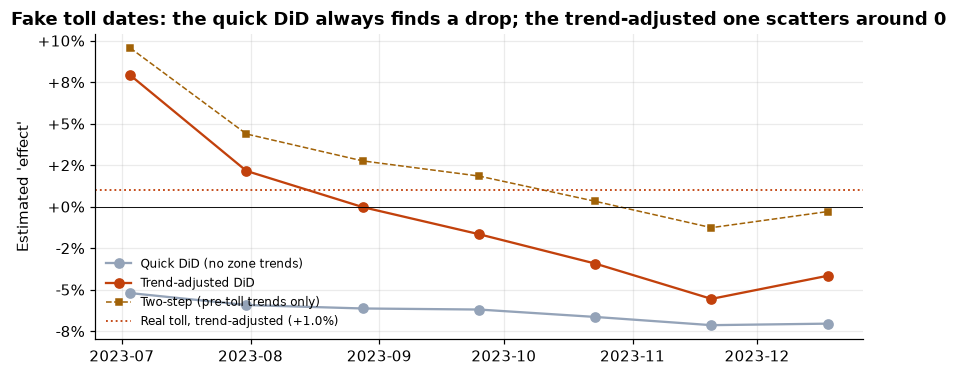

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = pd.to_datetime(fake["fake_start"])
ax.plot(x, fake["quick"], "o-", color="#94A3B8", label="Quick DiD (no zone trends)")
ax.plot(x, fake["trend_adjusted"], "o-", color=COLORS["cbd"], label="Trend-adjusted DiD")
ax.plot(x, fake["pre_trend_two_step"], "s--", color="#A16207", ms=4, lw=1,
        label="Two-step (pre-toll trends only)")
ax.axhline(0, color="black", lw=0.6)
ax.axhline(r_main.pct, color=COLORS["cbd"], ls=":", lw=1.2, label=f"Real toll, trend-adjusted ({r_main.pct:+.1%})")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_ylabel("Estimated 'effect'")
ax.set_title("Fake toll dates: the quick DiD always finds a drop; the trend-adjusted one scatters around 0")
ax.legend(fontsize=8, loc="lower left")
save(fig, "03_fake_dates.png")
plt.show()

The quick design finds a 5-7% "drop" on every fake date: it reads the
CBD's ongoing decline as an effect. The trend-adjusted design has no
such bias, but it is noisy: its fake effects range from about −6% to +8%,
with a typical size of about 4%, much wider than the formal confidence
interval. (These runs have a shorter pre-period than the main estimate,
so they likely overstate its noise somewhat.)

The trend-adjusted model fits each zone's trend over the whole window,
toll year included, so an effect that builds up over the year could be
partly absorbed into the trend. The **two-step** variant (third column)
fits each zone's trend on pre-toll weeks only and extends it forward; on
the real toll it gives a similar answer (section 5), and on fake dates it
is no less noisy.

So the honest reading of section 4 is **no detectable effect on trips**,
with this method alone unable to rule out an effect of a few percent
either way. Notebooks 04 and 05 check the answer with methods that have
different weaknesses.

## 5. Robustness

In [9]:
rows = []


def add(label, service, comp, spec, panel, **kw):
    r = fit_did(panel, **kw)
    rows.append({"specification": label, "service": service, "comparison": comp, "type": spec,
                 "effect": r.pct, "ci_low": r.pct_ci[0], "ci_high": r.pct_ci[1],
                 "treated_zones": r.n_treated_units, "comparison_units": r.n_control_units})


SERV = {("yellow", "hvfhv"): "Taxi + Uber/Lyft", ("hvfhv",): "Uber/Lyft", ("yellow",): "Yellow taxi"}
for svc, name in SERV.items():
    comps = ["manhattan_north"] if svc == ("yellow",) else ["manhattan_north", "outer", "both"]
    for comp in comps:
        p = comparison(panels[svc], comp)
        cname = {"manhattan_north": "Rest of Manhattan", "outer": "Outer boroughs", "both": "Both"}[comp]
        q = window(p, Y2024[0], Y2025[1], Y2025[0])
        q = q[(q["week"] <= Y2024[1]) | (q["week"] >= Y2025[0])]
        add("2025 vs 2024", name, cname, "quick", q, weights="pre_mean_trips")
        q = window(p, Y2023[0], Y2024[1], Y2024[0])
        q = q[(q["week"] <= Y2023[1]) | (q["week"] >= Y2024[0])]
        add("2024 vs 2023 (no toll)", name, cname, "placebo", q, weights="pre_mean_trips")
        add("Zone trends, 2023-2025", name, cname, "trend-adjusted",
            window(p, WINDOW_START, YEAR1_END), weights="pre_mean_trips", unit_trends=True)

add("Zone trends, unweighted", "Taxi + Uber/Lyft", "Rest of Manhattan", "trend-adjusted",
    main_win, unit_trends=True)
add("Zone trends, from 2022", "Taxi + Uber/Lyft", "Rest of Manhattan", "trend-adjusted",
    window(MAIN, "2022-01-03", YEAR1_END), weights="pre_mean_trips", unit_trends=True)
r_two_step = fit_did_pre_trend(main_win, weights="pre_mean_trips")
rows.append({"specification": "Zone trends from pre-toll weeks only (two-step)", "service": "Taxi + Uber/Lyft",
             "comparison": "Rest of Manhattan", "type": "trend-adjusted", "effect": r_two_step.pct,
             "ci_low": r_two_step.pct_ci[0], "ci_high": r_two_step.pct_ci[1],
             "treated_zones": r_two_step.n_treated_units, "comparison_units": r_two_step.n_control_units})

flow = flow_week_panel(zd)
flow = flow[flow["pu_zone"].isin(MANHATTAN_ZONES)]
add("Within origin: trips into vs not into the CBD", "Taxi + Uber/Lyft", "Same origin zones",
    "trend-adjusted", window(flow, WINDOW_START, YEAR1_END), unit="unit",
    weights="pre_mean_trips", unit_trends=True)

robust = pd.DataFrame(rows)
robust.to_csv("reports/metrics/did_robustness.csv", index=False)
robust.style.format({"effect": "{:+.1%}", "ci_low": "{:+.1%}", "ci_high": "{:+.1%}"})

,specification,service,comparison,type,effect,ci_low,ci_high,treated_zones,comparison_units
0,2025 vs 2024,Taxi + Uber/Lyft,Rest of Manhattan,quick,-2.6%,-4.0%,-1.2%,38,22
1,2024 vs 2023 (no toll),Taxi + Uber/Lyft,Rest of Manhattan,placebo,-4.4%,-5.3%,-3.5%,38,22
2,"Zone trends, 2023-2025",Taxi + Uber/Lyft,Rest of Manhattan,trend-adjusted,+1.0%,-0.3%,+2.3%,38,22
3,2025 vs 2024,Taxi + Uber/Lyft,Outer boroughs,quick,-6.3%,-7.1%,-5.4%,38,188
4,2024 vs 2023 (no toll),Taxi + Uber/Lyft,Outer boroughs,placebo,-5.9%,-6.6%,-5.2%,38,188
5,"Zone trends, 2023-2025",Taxi + Uber/Lyft,Outer boroughs,trend-adjusted,+0.1%,-0.9%,+1.2%,38,188
6,2025 vs 2024,Taxi + Uber/Lyft,Both,quick,-5.7%,-6.6%,-4.8%,38,210
7,2024 vs 2023 (no toll),Taxi + Uber/Lyft,Both,placebo,-5.7%,-6.4%,-5.0%,38,210
8,"Zone trends, 2023-2025",Taxi + Uber/Lyft,Both,trend-adjusted,+0.3%,-0.8%,+1.3%,38,210
9,2025 vs 2024,Uber/Lyft,Rest of Manhattan,quick,-4.6%,-6.1%,-3.1%,38,22


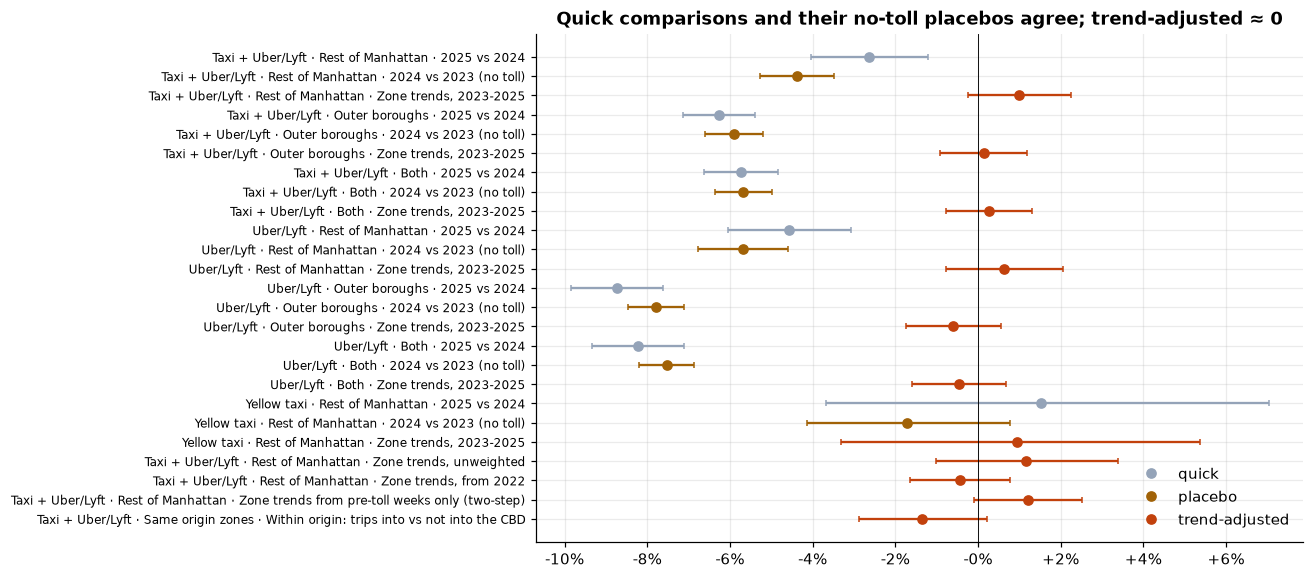

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
show = robust.copy()
show["label"] = show["service"] + " · " + show["comparison"] + " · " + show["specification"]
colors = {"quick": "#94A3B8", "placebo": "#A16207", "trend-adjusted": COLORS["cbd"]}
for i, row in show.iloc[::-1].reset_index(drop=True).iterrows():
    ax.errorbar(row["effect"], i, xerr=[[row["effect"] - row["ci_low"]], [row["ci_high"] - row["effect"]]],
                fmt="o", color=colors[row["type"]], capsize=2)
ax.set_yticks(range(len(show)))
ax.set_yticklabels(show["label"].iloc[::-1], fontsize=8)
ax.axvline(0, color="black", lw=0.6)
ax.xaxis.set_major_locator(plt.MultipleLocator(0.02))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
for k, c in colors.items():
    ax.errorbar([], [], fmt="o", color=c, label=k)
ax.legend(loc="lower right")
ax.set_title("Quick comparisons and their no-toll placebos agree; trend-adjusted ≈ 0")
save(fig, "03_robustness.png")
plt.show()

Reading the table:

* Every **quick** 2025-vs-2024 comparison is negative, and so is every
  **placebo** 2024-vs-2023 comparison, by a similar amount.
* The **trend-adjusted** estimates sit near zero for every service and
  comparison group, weighted or not, and in the within-origin design
  (from the same Manhattan zones, trips into the CBD against trips
  elsewhere), which cancels anything that hits a neighbourhood as a whole.
* The **two-step** version, with zone trends fitted on pre-toll weeks only,
  agrees with the main estimate, so the main result is not an artefact of
  fitting trends through the toll year.
* The outer-borough comparison is the noisiest; trips there grew fast in
  2024-2026 for reasons unrelated to the toll.

## 6. What else changed?

Same trend-adjusted design (CBD zones against the rest of Manhattan), now
on per-trip outcomes, each run on the same seven fake dates as in 4b and
on the fake January 2024 toll. An effect only counts if its CI excludes
zero and it is at least twice the size of both: the typical fake-date
effect and the fake-2024 effect for that outcome. These outcomes average
over all trips from a zone, so comparison zones include their trips into
the CBD (about a quarter of them), which biases estimates toward zero.

In [11]:
OUTCOMES = {
    "log_trips": "Trips (main estimate)",
    "log_trips_peak": "Trips in car-toll peak hours",
    "log_trips_offpeak": "Trips overnight (car toll $2.25)",
    "log_shared_requests": "Shared-ride requests",
    "log_mph": "Average trip speed",
    "log_minutes": "Trip duration",
    "log_fare": "Fare per trip (before fees and tips)",
    "log_pay_per_hour": "Driver pay per hour on trip",
    "log_wait": "Wait from request to pickup",
}
out_rows = [{"service": "Taxi + Uber/Lyft", "outcome": OUTCOMES["log_trips"],
             "effect": r_main.pct, "ci_low": r_main.pct_ci[0], "ci_high": r_main.pct_ci[1],
             "placebo_2024": r_pl_trend.pct, "fake_rms": fake_rms["trend_adjusted"],
             "fake_max_abs": float(fake["trend_adjusted"].abs().max())}]
for svc in ["hvfhv", "yellow"]:
    o = zone_week_outcomes(zd, svc)
    o = o[o["group"].isin(["cbd", "manhattan_north"])]
    for col, label in OUTCOMES.items():
        if col == "log_trips" or col not in o or o[col].isna().all():
            continue
        if svc == "yellow" and col.startswith("log_trips_"):
            continue   # taxi trips split by hour are too noisy at the zone level
        oo = o.dropna(subset=[col])
        r = fit_did(window(oo, WINDOW_START, YEAR1_END), y=col, weights="trips", unit_trends=True)
        pre_oo = oo[oo["week"] < pd.Timestamp("2024-12-30")]
        fakes = np.array([fit_did(window(pre_oo, "2022-07-04", d + pd.Timedelta(weeks=51), d), y=col,
                                  weights="trips", unit_trends=True).pct for d in FAKE_DATES])
        pl = fit_did(window(oo, "2022-07-04", Y2024[1], Y2024[0]), y=col, weights="trips",
                     unit_trends=True)
        out_rows.append({"service": "Uber/Lyft" if svc == "hvfhv" else "Yellow taxi", "outcome": label,
                         "effect": r.pct, "ci_low": r.pct_ci[0], "ci_high": r.pct_ci[1],
                         "placebo_2024": pl.pct, "fake_rms": float(np.sqrt((fakes ** 2).mean())),
                         "fake_max_abs": float(np.abs(fakes).max())})
other = pd.DataFrame(out_rows)
# Clear: the CI excludes zero, and the effect is at least twice both the
# typical fake-date effect and the fake-2024 effect for the same outcome.
other["clear"] = (((other["ci_low"] > 0) | (other["ci_high"] < 0))
                  & (other["effect"].abs() >= 2 * other["fake_rms"])
                  & (other["effect"].abs() >= 2 * other["placebo_2024"].abs()))
other.to_csv("reports/metrics/did_other_outcomes.csv", index=False)
other.style.format({c: "{:+.1%}" for c in ["effect", "ci_low", "ci_high", "placebo_2024"]} |
                   {c: "{:.1%}" for c in ["fake_rms", "fake_max_abs"]})

,service,outcome,effect,ci_low,ci_high,placebo_2024,fake_rms,fake_max_abs,clear
0,Taxi + Uber/Lyft,Trips (main estimate),+1.0%,-0.3%,+2.3%,+2.0%,4.3%,7.9%,False
1,Uber/Lyft,Trips in car-toll peak hours,+2.0%,+0.6%,+3.3%,+1.7%,2.8%,5.5%,False
2,Uber/Lyft,Trips overnight (car toll $2.25),+0.5%,-1.7%,+2.8%,+0.8%,5.5%,7.2%,False
3,Uber/Lyft,Shared-ride requests,-12.7%,-17.7%,-7.5%,+6.2%,3.1%,6.3%,True
4,Uber/Lyft,Average trip speed,+5.0%,+4.2%,+5.7%,+1.1%,1.7%,3.5%,True
5,Uber/Lyft,Trip duration,-5.2%,-5.9%,-4.5%,-4.8%,2.3%,4.7%,False
6,Uber/Lyft,Fare per trip (before fees and tips),-2.9%,-4.0%,-1.8%,-4.4%,3.1%,5.2%,False
7,Uber/Lyft,Driver pay per hour on trip,+2.7%,+2.3%,+3.1%,+0.0%,1.0%,2.2%,True
8,Uber/Lyft,Wait from request to pickup,-5.7%,-7.7%,-3.6%,+1.2%,3.7%,6.7%,False
9,Yellow taxi,Average trip speed,+4.4%,+3.0%,+5.8%,+1.2%,1.8%,4.4%,True


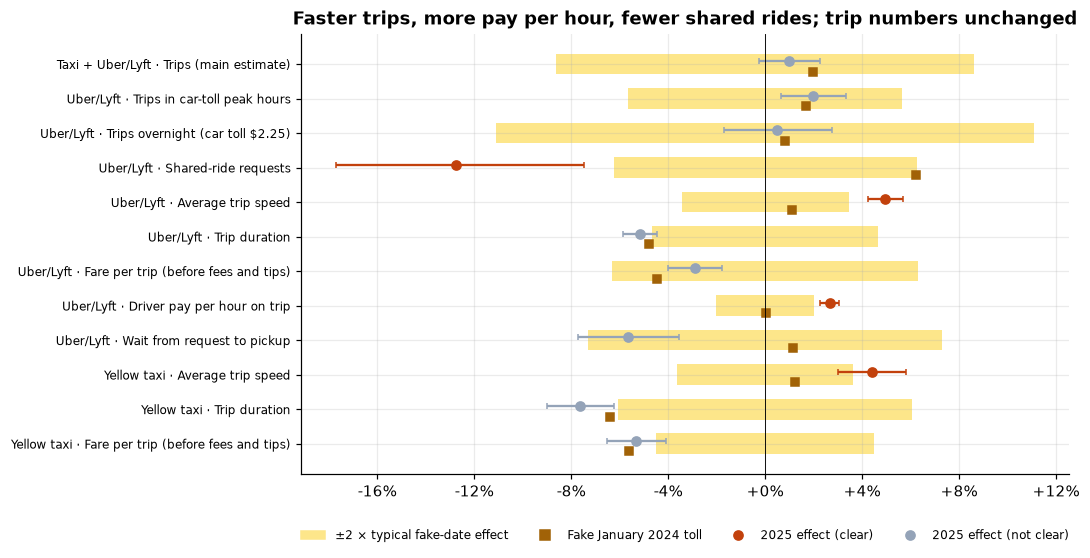

In [12]:
fig, ax = plt.subplots(figsize=(9, 5.2))
lab = other["service"] + " · " + other["outcome"]
n = len(other)
for i, row in other.iloc[::-1].reset_index(drop=True).iterrows():
    ax.fill_betweenx([i - 0.3, i + 0.3], -2 * row["fake_rms"], 2 * row["fake_rms"], color="#FDE68A", lw=0)
    ax.plot(row["placebo_2024"], i - 0.22, "s", ms=5, color="#A16207")
    ax.errorbar(row["effect"], i + 0.08, xerr=[[row["effect"] - row["ci_low"]], [row["ci_high"] - row["effect"]]],
                fmt="o", color=COLORS["cbd"] if row["clear"] else "#94A3B8", capsize=2)
ax.set_yticks(range(n))
ax.set_yticklabels(lab.iloc[::-1], fontsize=8)
ax.axvline(0, color="black", lw=0.6)
ax.xaxis.set_major_locator(plt.MultipleLocator(0.04))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.errorbar([], [], fmt="o", color=COLORS["cbd"], label="2025 effect (clear)")
ax.errorbar([], [], fmt="o", color="#94A3B8", label="2025 effect (not clear)")
ax.fill_between([], [], color="#FDE68A", label="±2 × typical fake-date effect")
ax.plot([], [], "s", color="#A16207", label="Fake January 2024 toll")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, fontsize=8)
ax.set_title("Faster trips, more pay per hour, fewer shared rides; trip numbers unchanged")
save(fig, "03_other_outcomes.png")
plt.show()

Four effects clear that bar:

* **Speed:** trips starting in the CBD got about 4-5% faster (Uber/Lyft
  and taxis alike), consistent with road-speed studies of the toll.
* **Driver pay per hour on trip** rose about 3%: the same trips take less
  time and pay is partly per trip.
* **Shared-ride requests** from the CBD fell by roughly an eighth. The
  $1.50 fee is charged per rider with no discount for sharing, so it
  raises the price of a cheap shared ride by more, in percent, than a
  private one. An early study of the first 14 weeks found a 38% drop; the
  trend-adjusted, full-year estimate here is smaller but clear.

Uber/Lyft trips at car-toll peak hours and overnight both show no clear
change, so
the toll did not visibly shift ride-hail demand between times of day.

Uber/Lyft **waits** fell about 6%, which fits faster traffic, but this
outcome is noisy on fake dates too, so it is reported as suggestive.
Trip duration and fare per trip also fell, but they fell almost as much
around the fake January 2024 toll, so they are not attributed to the toll.

## 7. How much did the fee raise the price of a CBD trip?

The per-trip fee as a share of the fare before fees and tips, for trips
starting in the CBD in 2025. Notebook 06 combines this with the trip
estimates into a bound on how sensitive demand is to price.

In [13]:
y25 = zd[(zd["group"] == "cbd") & (zd["date"].dt.year == 2025) & zd["service"].isin(["yellow", "hvfhv"])]
fees = y25.groupby("service")[["fee_sum", "fare_sum", "trips"]].sum()
fees["fee_per_trip"] = fees["fee_sum"] / fees["trips"]
fees["fare_per_trip"] = fees["fare_sum"] / fees["trips"]
fees["fee_share_of_fare"] = fees["fee_sum"] / fees["fare_sum"]
pooled_fee_share = float(fees["fee_sum"].sum() / fees["fare_sum"].sum())
print(f"Fee as a share of the fare, CBD trips, 2025 (taxi + Uber/Lyft): {pooled_fee_share:.1%}")
fees.rename(index=SERVICE_LABEL).style.format({"fee_sum": "${:,.0f}", "fare_sum": "${:,.0f}", "trips": "{:,.0f}",
                                               "fee_per_trip": "${:.2f}", "fare_per_trip": "${:.2f}",
                                               "fee_share_of_fare": "{:.1%}"})

Fee as a share of the fare, CBD trips, 2025 (taxi + Uber/Lyft): 4.3%


,fee_sum,fare_sum,trips,fee_per_trip,fare_per_trip,fee_share_of_fare
service,,,,,,
Uber/Lyft,"$89,377,048","$2,076,064,032","60,688,141",$1.47,$34.21,4.3%
Yellow taxi,"$18,907,591","$437,754,300","25,622,153",$0.74,$17.08,4.3%


The fee adds about 4% to the price of a CBD trip for both services
(taxis pay half the fee on fares about half as large).

In [14]:
def res(r):
    return {"effect": r.pct, "ci_low": r.pct_ci[0], "ci_high": r.pct_ci[1], "p_value": r.p_value,
            "treated_zones": r.n_treated_units, "comparison_zones": r.n_control_units}


write_metrics("did", {
    "quick_2025_vs_2024": res(r_quick),
    "placebo_2024_vs_2023": res(r_placebo),
    "main_trend_adjusted_year1": res(r_main),
    "trend_adjusted_year2_2026": res(r_y2),
    "placebo_trend_adjusted_2024": res(r_pl_trend),
    "fake_dates": {"dates": [d.date().isoformat() for d in FAKE_DATES],
                   "quick_rms": fake_rms["quick"], "trend_adjusted_rms": fake_rms["trend_adjusted"],
                   "two_step_rms": fake_rms["pre_trend_two_step"],
                   "quick_range": [float(fake["quick"].min()), float(fake["quick"].max())],
                   "trend_adjusted_range": [float(fake["trend_adjusted"].min()),
                                            float(fake["trend_adjusted"].max())]},
    "pre_trend_per_year": float(np.expm1(slope * 4)),
    "two_step_pre_trend_year1": res(r_two_step),
    "fee_share_of_fare_2025": pooled_fee_share,
    "fee_per_trip_2025": {SERVICE_LABEL[k]: float(v) for k, v in fees["fee_per_trip"].items()},
    "other_outcomes": {f"{r['service']} | {r['outcome']}": {
        **{k: float(r[k]) for k in ["effect", "ci_low", "ci_high", "placebo_2024", "fake_rms",
                                    "fake_max_abs"]},
        "clear": bool(r["clear"])}
        for _, r in other.iterrows()},
    "robustness_trend_adjusted_range": [float(robust.loc[robust["type"] == "trend-adjusted", "effect"].min()),
                                        float(robust.loc[robust["type"] == "trend-adjusted", "effect"].max())],
})

Saved reports/metrics/did.json
